In [327]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ayushbharti96/boston-housing-price-analysis-and-prediction/Boston-house-price-data.csv


In [328]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [329]:
df = pd.read_csv('/kaggle/input/datasets/ayushbharti96/boston-housing-price-analysis-and-prediction/Boston-house-price-data.csv')

In [330]:
#Display the first 10 rows and last 5 rows.
df.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9


In [331]:
df.tail(5)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0,0.573,6.030,80.8,2.5050,1,273.0,21.0,396.90,7.88,11.9


In [332]:
#Find the total number of rows and columns.
df.shape

(506, 14)

In [333]:
 #Display all column names.
df.columns

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')

In [334]:
#Check the data types of all columns
df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX        float64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

In [335]:
#Check missing values in each column.
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [336]:
#Check duplicate records.
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
501    False
502    False
503    False
504    False
505    False
Length: 506, dtype: bool

In [337]:
#Find the unique values in the CHAS column.
df['CHAS'].unique()

array([0, 1])

In [338]:
#Check the statistical summary using describe().
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [339]:
#Find the total number of houses with each CHAS value.
df['CHAS'].value_counts()

CHAS
0    471
1     35
Name: count, dtype: int64

In [340]:
#Calculate the average house price (MEDV).
df['MEDV'].mean()

np.float64(22.532806324110677)

In [341]:
#Find the minimum and maximum house prices.
print('Maximum price :',df['MEDV'].max())
print('minimum price :',df['MEDV'].min())

Maximum price : 50.0
minimum price : 5.0


In [342]:
#Calculate Q1, Q3 and IQR of MEDV.
Q1 = df['MEDV'].quantile(0.25)
Q3 = df['MEDV'].quantile(0.75)

IQR = Q3 - Q1
print('Q1',Q1)
print('Q3',Q3)
print('IQR',IQR)

Q1 17.025
Q3 25.0
IQR 7.975000000000001


In [343]:
#Find the standard deviation of house prices.
df['MEDV'].std()

9.19710408737982

In [344]:
#Calculate the average number of rooms (RM).
df['RM'].mean()

np.float64(6.284634387351779)

In [345]:
#Find the average crime rate (CRIM).
df['CRIM'].mean()

np.float64(3.613523557312254)

In [346]:
#Calculate the average pollution level (NOX)
df['NOX'].mean()

np.float64(0.5546950592885376)

In [347]:
#Find the average property tax (TAX).
df['TAX'].mean()

np.float64(408.2371541501976)

In [348]:
#Calculate the correlation between all numerical columns.
df.corr()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,-0.385064,0.455621,-0.388305
ZN,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,0.175520,-0.412995,0.360445
INDUS,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,-0.356977,0.603800,-0.483725
CHAS,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,0.048788,-0.053929,0.175260
NOX,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,-0.380051,0.590879,-0.427321
RM,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,0.128069,-0.613808,0.695360
AGE,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,-0.273534,0.602339,-0.376955
DIS,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,0.291512,-0.496996,0.249929
RAD,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,-0.444413,0.488676,-0.381626
TAX,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,-0.441808,0.543993,-0.468536


In [349]:
#Find the top 10 most expensive houses based on MEDV.
df.sort_values(by='MEDV',ascending=False).head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
369,5.66998,0.0,18.10,1,0.6310,6.683,96.8,1.3567,24,666.0,20.2,375.33,3.73,50.0
372,8.26725,0.0,18.10,1,0.6680,5.875,89.6,1.1296,24,666.0,20.2,347.88,8.88,50.0
371,9.23230,0.0,18.10,0,0.6310,6.216,100.0,1.1691,24,666.0,20.2,366.15,9.53,50.0
370,6.53876,0.0,18.10,1,0.6310,7.016,97.5,1.2024,24,666.0,20.2,392.05,2.96,50.0
368,4.89822,0.0,18.10,0,0.6310,4.970,100.0,1.3325,24,666.0,20.2,375.52,3.26,50.0
267,0.57834,20.0,3.97,0,0.5750,8.297,67.0,2.4216,5,264.0,13.0,384.54,7.44,50.0
166,2.01019,0.0,19.58,0,0.6050,7.929,96.2,2.0459,5,403.0,14.7,369.30,3.70,50.0
163,1.51902,0.0,19.58,1,0.6050,8.375,93.9,2.1620,5,403.0,14.7,388.45,3.32,50.0
186,0.05602,0.0,2.46,0,0.4880,7.831,53.6,3.1992,3,193.0,17.8,392.63,4.45,50.0
204,0.02009,95.0,2.68,0,0.4161,8.034,31.9,5.1180,4,224.0,14.7,390.55,2.88,50.0


In [350]:
#Find houses having more than 6 rooms (RM).
df[df['RM']>6]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


In [351]:
#Find houses with a crime rate (CRIM) greater than 5.
df[df['CRIM']>5]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
356,8.98296,0.0,18.1,1,0.770,6.212,97.4,2.1222,24,666.0,20.2,377.73,17.60,17.8
358,5.20177,0.0,18.1,1,0.770,6.127,83.4,2.7227,24,666.0,20.2,395.43,11.48,22.7
367,13.52220,0.0,18.1,0,0.631,3.863,100.0,1.5106,24,666.0,20.2,131.42,13.33,23.1
369,5.66998,0.0,18.1,1,0.631,6.683,96.8,1.3567,24,666.0,20.2,375.33,3.73,50.0
370,6.53876,0.0,18.1,1,0.631,7.016,97.5,1.2024,24,666.0,20.2,392.05,2.96,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,14.33370,0.0,18.1,0,0.614,6.229,88.0,1.9512,24,666.0,20.2,383.32,13.11,21.4
480,5.82401,0.0,18.1,0,0.532,6.242,64.7,3.4242,24,666.0,20.2,396.90,10.74,23.0
481,5.70818,0.0,18.1,0,0.532,6.750,74.9,3.3317,24,666.0,20.2,393.07,7.74,23.7
482,5.73116,0.0,18.1,0,0.532,7.061,77.0,3.4106,24,666.0,20.2,395.28,7.01,25.0


In [352]:
#Find houses where MEDV is greater than 30.
df[df['MEDV']>30]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
39,0.02763,75.0,2.95,0,0.428,6.595,21.8,5.4011,3,252.0,18.3,395.63,4.32,30.8
40,0.03359,75.0,2.95,0,0.428,7.024,15.8,5.4011,3,252.0,18.3,395.62,1.98,34.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368,4.89822,0.0,18.10,0,0.631,4.970,100.0,1.3325,24,666.0,20.2,375.52,3.26,50.0
369,5.66998,0.0,18.10,1,0.631,6.683,96.8,1.3567,24,666.0,20.2,375.33,3.73,50.0
370,6.53876,0.0,18.10,1,0.631,7.016,97.5,1.2024,24,666.0,20.2,392.05,2.96,50.0
371,9.23230,0.0,18.10,0,0.631,6.216,100.0,1.1691,24,666.0,20.2,366.15,9.53,50.0


In [353]:
#Find houses with NOX greater than 0.5.
df[df['NOX']>0.5]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


In [354]:
#Find houses with LSTAT less than 10.
df[df['LSTAT']<10]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


In [355]:
#Calculate the average MEDV for houses with RM greater than 6.
df[df['RM'] >6]['MEDV'].mean()

np.float64(25.164264264264265)

In [356]:
#Compare average MEDV for CHAS = 0 and CHAS = 1.
print("CHAS 0:", df[df['CHAS'] == 0]['MEDV'].mean())

print("CHAS 1:", df[df['CHAS'] == 1]['MEDV'].mean())

CHAS 0: 22.093842887473464
CHAS 1: 28.439999999999998


In [357]:
#Find the average MEDV for houses with TAX greater than 300.
df[df['TAX'] >300] ['MEDV'].mean()

np.float64(20.168263473053894)

In [358]:
#Find the top 10 areas with the lowest crime rates.
df.sort_values(by='CRIM',ascending =False).head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
380,88.9762,0.0,18.1,0,0.671,6.968,91.9,1.4165,24,666.0,20.2,396.90,17.21,10.4
418,73.5341,0.0,18.1,0,0.679,5.957,100.0,1.8026,24,666.0,20.2,16.45,20.62,8.8
405,67.9208,0.0,18.1,0,0.693,5.683,100.0,1.4254,24,666.0,20.2,384.97,22.98,5.0
410,51.1358,0.0,18.1,0,0.597,5.757,100.0,1.4130,24,666.0,20.2,2.60,10.11,15.0
414,45.7461,0.0,18.1,0,0.693,4.519,100.0,1.6582,24,666.0,20.2,88.27,36.98,7.0
404,41.5292,0.0,18.1,0,0.693,5.531,85.4,1.6074,24,666.0,20.2,329.46,27.38,8.5
398,38.3518,0.0,18.1,0,0.693,5.453,100.0,1.4896,24,666.0,20.2,396.90,30.59,5.0
427,37.6619,0.0,18.1,0,0.679,6.202,78.7,1.8629,24,666.0,20.2,18.82,14.52,10.9
413,28.6558,0.0,18.1,0,0.597,5.155,100.0,1.5894,24,666.0,20.2,210.97,20.08,16.3
417,25.9406,0.0,18.1,0,0.679,5.304,89.1,1.6475,24,666.0,20.2,127.36,26.64,10.4


In [359]:
#Identify houses with high prices and low crime rates.
df[(df['MEDV'] > 30) & (df['CRIM'] < 1)]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
39,0.02763,75.0,2.95,0,0.428,6.595,21.8,5.4011,3,252.0,18.3,395.63,4.32,30.8
40,0.03359,75.0,2.95,0,0.428,7.024,15.8,5.4011,3,252.0,18.3,395.62,1.98,34.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,0.05515,33.0,2.18,0,0.472,7.236,41.1,4.0220,7,222.0,18.4,393.68,6.93,36.1
306,0.07503,33.0,2.18,0,0.472,7.420,71.9,3.0992,7,222.0,18.4,396.90,6.47,33.4
341,0.01301,35.0,1.52,0,0.442,7.241,49.3,7.0379,1,284.0,15.5,394.74,5.49,32.7
344,0.03049,55.0,3.78,0,0.484,6.874,28.1,6.4654,5,370.0,17.6,387.97,4.61,31.2


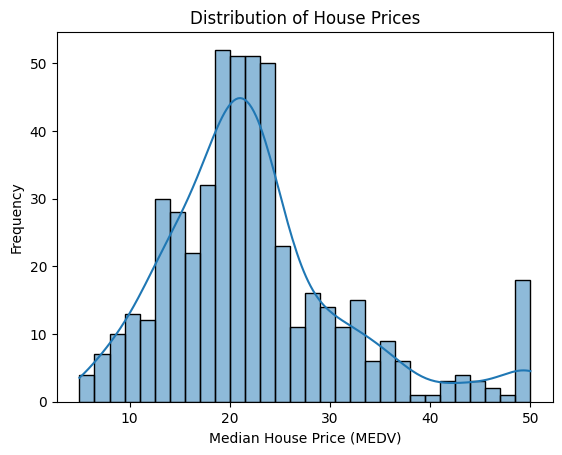

In [360]:
#Create a histogram of MEDV.
sns.histplot(df['MEDV'],bins=30,kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Median House Price (MEDV)")
plt.ylabel("Frequency")
plt.show()

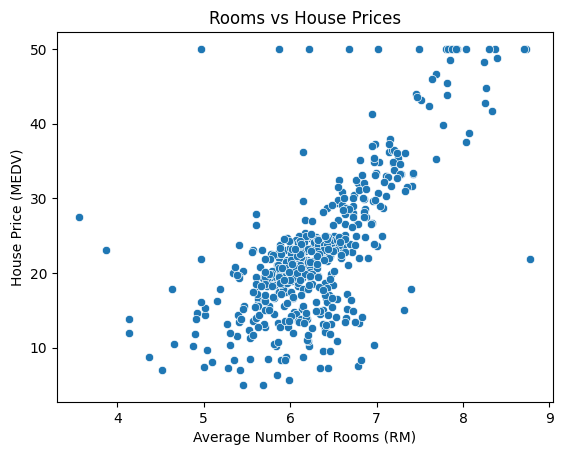

In [361]:
#Create a scatter plot between RM and MEDV.
sns.scatterplot(x='RM', y='MEDV',data = df)
plt.title("Rooms vs House Prices")
plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("House Price (MEDV)")
plt.show()

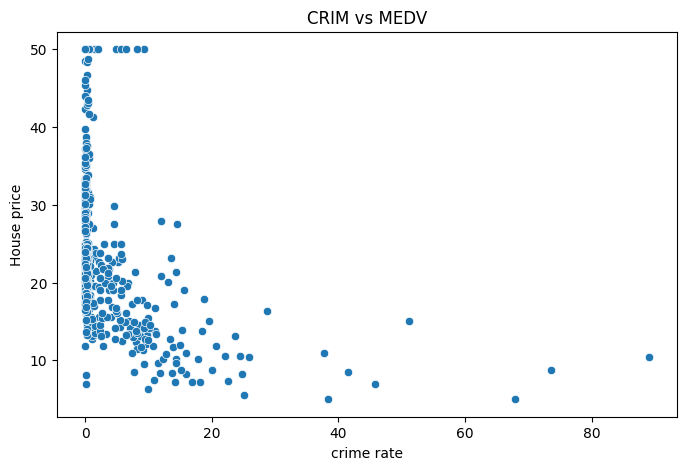

In [362]:
#Create a scatter plot between CRIM and MEDV.
plt.figure(figsize=(8, 5))
sns.scatterplot(x ='CRIM', y = 'MEDV',data = df)
plt.title("CRIM vs MEDV")
plt.xlabel("crime rate")
plt.ylabel("House price")
plt.show()

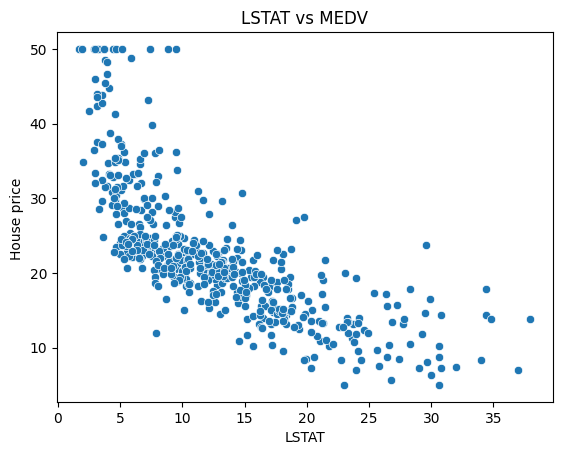

In [363]:
#Create a scatter plot between LSTAT and MEDV.
sns.scatterplot(x ='LSTAT', y = 'MEDV', data = df)
plt.title("LSTAT vs MEDV")
plt.xlabel("LSTAT")
plt.ylabel("House price ")
plt.show()

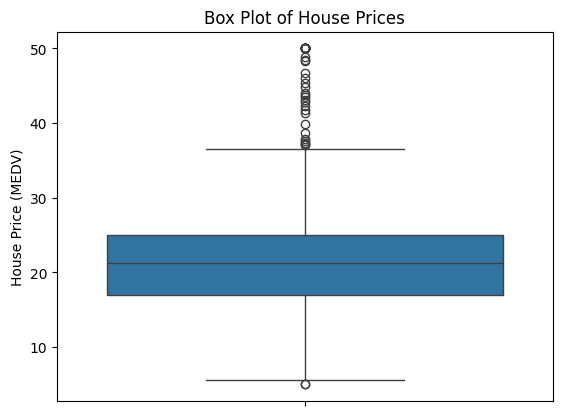

In [364]:
#Create a box plot of MEDV to identify outliers.
sns.boxplot(y=df['MEDV'])
plt.title("Box Plot of House Prices")
plt.ylabel("House Price (MEDV)")
plt.show()

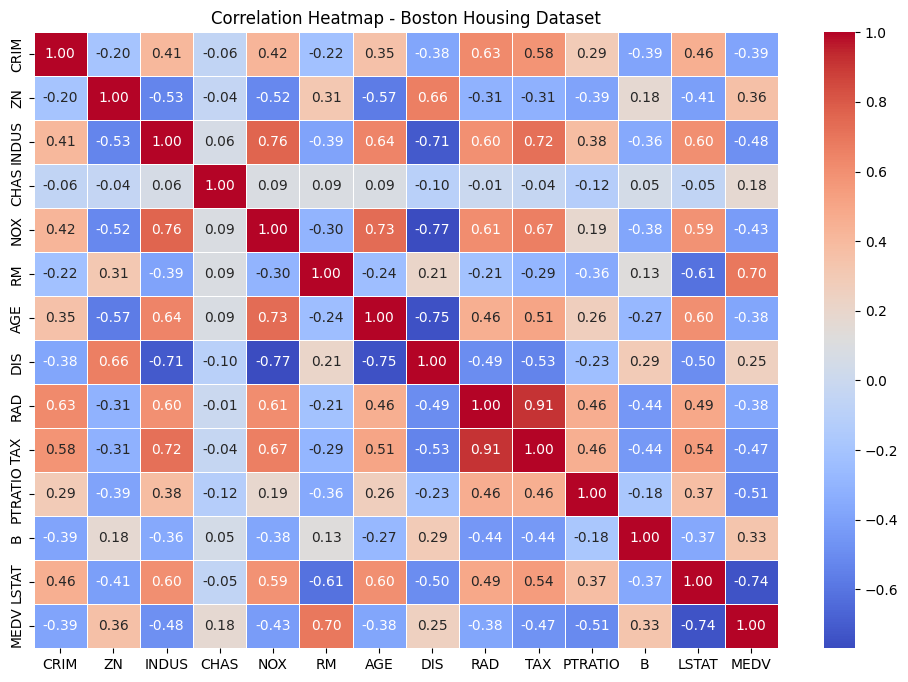

In [365]:
#Create a heatmap of the correlation matrix.
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(),annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)

plt.title("Correlation Heatmap - Boston Housing Dataset")
plt.show()

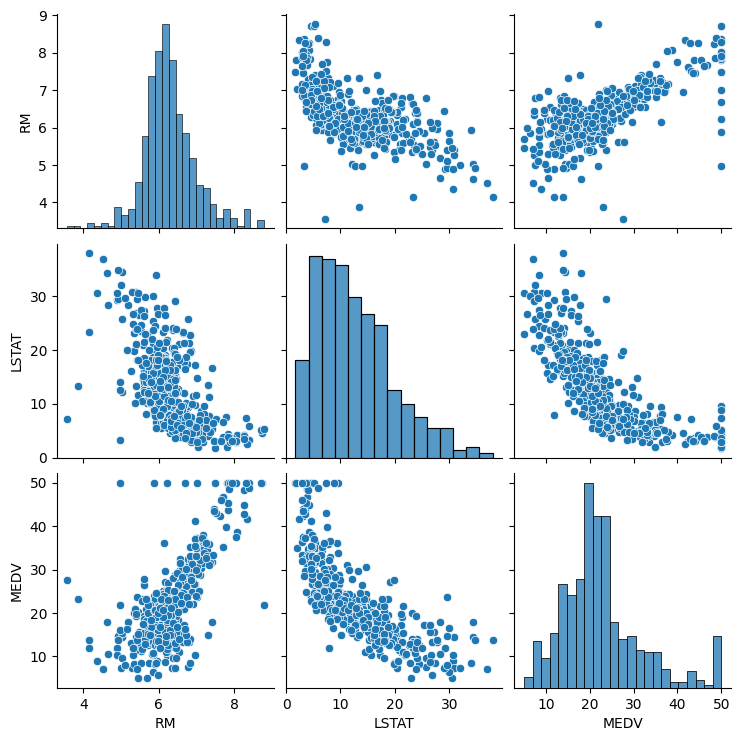

In [366]:
#Create a pair plot between RM, LSTAT and MEDV.
sns.pairplot(df[['RM', 'LSTAT', 'MEDV']])

plt.show()

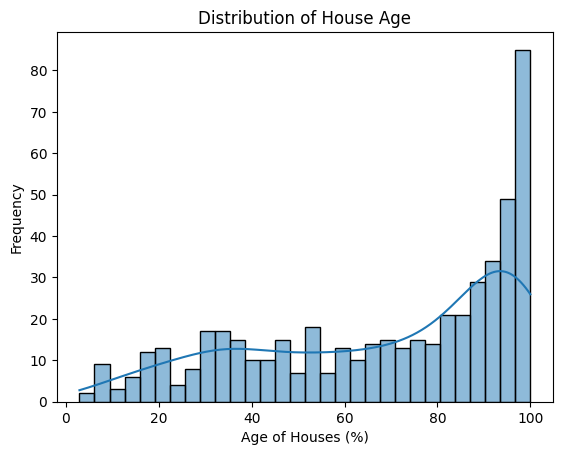

In [367]:
#Create a histogram of AGE.
sns.histplot(df['AGE'], bins=30, kde=True)

plt.title("Distribution of House Age")
plt.xlabel("Age of Houses (%)")
plt.ylabel("Frequency")
plt.show()

In [368]:
#Which feature has the strongest correlation with MEDV?
correlation = df.corr()['MEDV'].drop('MEDV')
correlation.abs().sort_values(ascending=False)

LSTAT      0.737663
RM         0.695360
PTRATIO    0.507787
INDUS      0.483725
TAX        0.468536
NOX        0.427321
CRIM       0.388305
RAD        0.381626
AGE        0.376955
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
Name: MEDV, dtype: float64

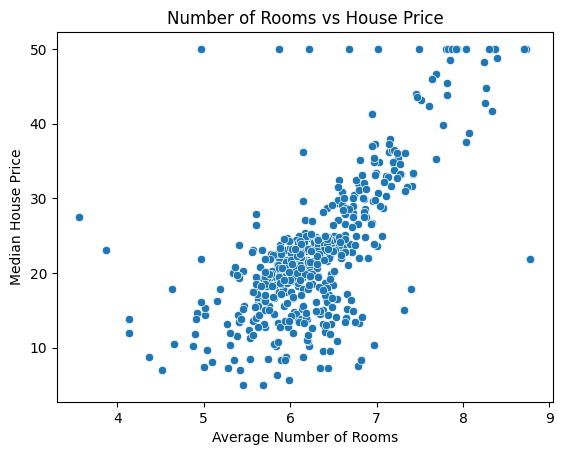

In [369]:
#Does the number of rooms (RM) affect house prices?

sns.scatterplot(x='RM', y='MEDV', data=df)

plt.title("Number of Rooms vs House Price")
plt.xlabel("Average Number of Rooms")
plt.ylabel("Median House Price")
plt.show()

Correlation between CRIM and MEDV: -0.38830460858681143


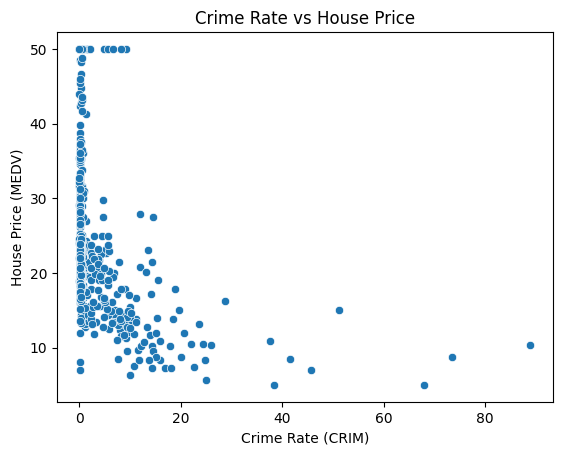

In [370]:
#Does a higher crime rate decrease house prices?
correlation = df['CRIM'].corr(df['MEDV'])

print("Correlation between CRIM and MEDV:", correlation)
sns.scatterplot(x='CRIM', y='MEDV', data=df)

plt.title("Crime Rate vs House Price")
plt.xlabel("Crime Rate (CRIM)")
plt.ylabel("House Price (MEDV)")
plt.show()

Correlation between NOX and MEDV: -0.4273207723732826


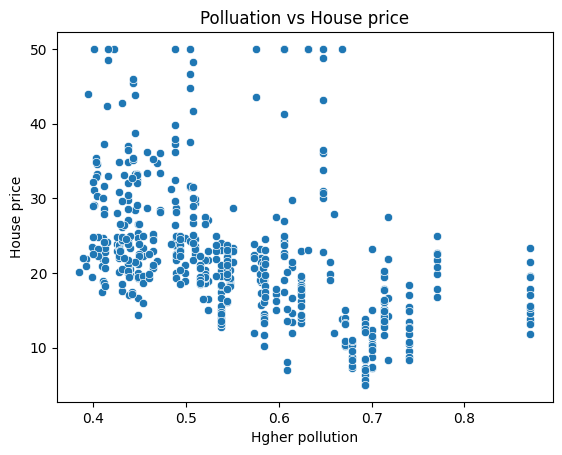

In [371]:
#Does higher pollution (NOX) affect house prices?
correlation = df['NOX'].corr(df['MEDV'])

print("Correlation between NOX and MEDV:", correlation)
sns.scatterplot(x='NOX',y='MEDV',data=df)
plt.title("Polluation vs House price")
plt.xlabel("Hgher pollution")
plt.ylabel("House price")
plt.show()

Correlation between LSTAT and MEDV: -0.7376627261740151


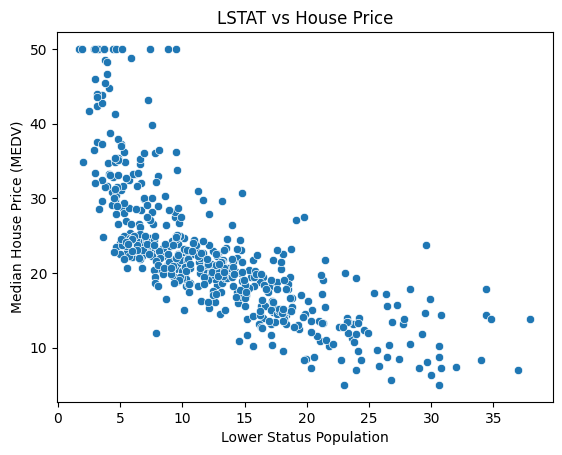

In [372]:
#How does LSTAT affect MEDV?
correlation = df['LSTAT'].corr(df['MEDV'])
print("Correlation between LSTAT and MEDV:", correlation)
sns.scatterplot(x='LSTAT', y='MEDV', data=df)

plt.title("LSTAT vs House Price")
plt.xlabel("Lower Status Population")
plt.ylabel("Median House Price (MEDV)")
plt.show()

Correlation between DIS and MEDV: 0.24992873408590394


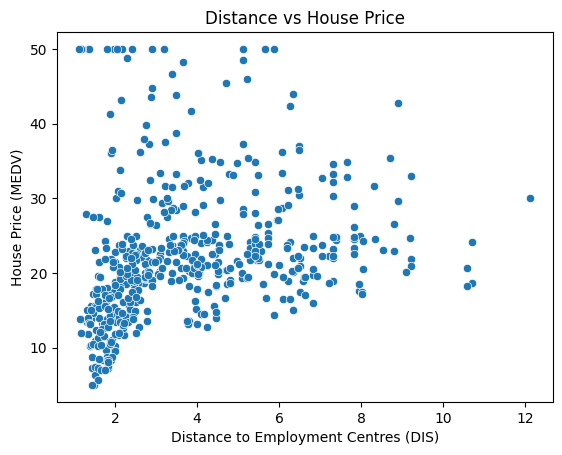

In [373]:
#Does proximity to employment centres (DIS) affect house prices?
correlation = df['DIS'].corr(df['MEDV'])

print("Correlation between DIS and MEDV:", correlation)
sns.scatterplot(x='DIS', y='MEDV', data=df)

plt.title("Distance vs House Price")
plt.xlabel("Distance to Employment Centres (DIS)")
plt.ylabel("House Price (MEDV)")
plt.show()

In [374]:
#Which features have a positive correlation with MEDV?
correlation = df.corr()['MEDV']

positive_corr = correlation[correlation > 0].drop('MEDV')

print(positive_corr.sort_values(ascending=False))

RM      0.695360
ZN      0.360445
B       0.333461
DIS     0.249929
CHAS    0.175260
Name: MEDV, dtype: float64


In [375]:
#Which features have a negative correlation with MEDV?
corr = df.corr()['MEDV']
neg_corr = corr[corr > 0].drop('MEDV')
print(neg_corr.sort_values(ascending=False))

RM      0.695360
ZN      0.360445
B       0.333461
DIS     0.249929
CHAS    0.175260
Name: MEDV, dtype: float64


In [376]:
#Identify the most important factors affecting house prices.
correlation = df.corr()['MEDV'].drop('MEDV')
imp = correlation.abs().sort_values(ascending=False)

print(imp)

LSTAT      0.737663
RM         0.695360
PTRATIO    0.507787
INDUS      0.483725
TAX        0.468536
NOX        0.427321
CRIM       0.388305
RAD        0.381626
AGE        0.376955
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
Name: MEDV, dtype: float64


In [377]:
#Predict house prices using Linear Regression with RM.
x =df[['RM']]
y =df[['MEDV']]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size =0.2,random_state = 42)
model = LinearRegression()
model.fit(x_train,y_train)

y_pred = model.predict(x_test)
model.predict(pd.DataFrame({'RM': [7]}))
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.3707569232254778


In [378]:
#Predict house prices using LSTAT.
x = df[['LSTAT']]
y = df[['MEDV']]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2 ,random_state = 42)
model = LinearRegression()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.5429180422970384


In [379]:
#Build a Multiple Linear Regression model using multiple features.
X = df[['RM', 'LSTAT', 'CRIM', 'PTRATIO']]
y = df['MEDV']

x_train,x_test,y_train,y_test = train_test_split(x , y, test_size = 0.2,random_state = 42)
model = LinearRegression()
model.fit(x_train,y_train)

y_pred = model.predict(x_test)
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.5429180422970384


In [380]:
#Split the dataset into 80% training and 20% testing.
X = df[['RM', 'LSTAT', 'CRIM', 'PTRATIO']]
y = df['MEDV']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (404, 4)
Testing data: (102, 4)


In [381]:
#Apply StandardScaler to the input features.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled[:5])

[[-1.42806858  1.75350503  1.28770177  0.84534281]
 [-0.68008655 -0.5614742  -0.33638447  1.20474139]
 [-0.40206304 -0.65159505 -0.40325332 -0.63717631]
 [-0.30045039  1.52538664  0.38822983  0.84534281]
 [-0.83109424 -0.16578736 -0.32528234  1.20474139]]


In [382]:
#Evaluate the model using MAE, MSE and R² score.
model = LinearRegression()
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 3.3729571748244145
MSE: 27.94860479138639
R2 Score: 0.6188849996967304


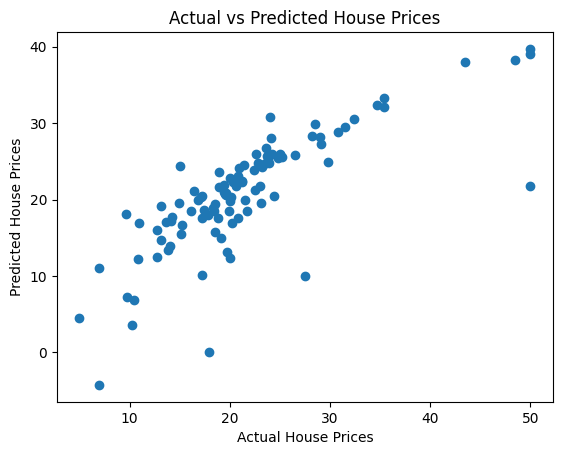

In [383]:
#Plot actual vs predicted house prices.
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()

In [384]:
#Predict the price of a new house using your trained model.
new_house = pd.DataFrame({'RM': [7],'LSTAT': [10],'CRIM': [0.5],'PTRATIO': [18]})

new_house_scaled = scaler.transform(new_house)

predicted_price = model.predict(new_house_scaled)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 28.06897015415986


In [385]:
#Train a Decision Tree Regressor.
model = DecisionTreeRegressor(random_state=42)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.7618945086684746


In [386]:
#Train a Random Forest Regressor.
model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.8476483878677058


In [387]:
#Compare Linear Regression, Decision Tree and Random Forest.
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    print(name, ":", r2_score(y_test, y_pred))

Linear Regression : 0.6188849996967303
Decision Tree : 0.7618945086684746
Random Forest : 0.8476483878677058


In [388]:
#Find feature importance using Random Forest.
importance = pd.Series(model.feature_importances_,index=X.columns)

print(importance.sort_values(ascending=False))

RM         0.524099
LSTAT      0.347340
CRIM       0.097816
PTRATIO    0.030745
dtype: float64


In [389]:
#Perform Hyperparameter Tuning using GridSearchCV.
from sklearn.model_selection import GridSearchCV
params = {
    'n_estimators': [50, 100],
    'max_depth': [None, 5, 10]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    params,
    cv=5,
    scoring='r2'
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best R2 Score:", grid.best_score_)

Best Parameters: {'max_depth': 5, 'n_estimators': 50}
Best R2 Score: 0.7919721419170855


In [390]:
#Identify the best regression model for house price prediction.
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    print(name, ":", r2_score(y_test, pred))

Linear Regression : 0.6188849996967303
Decision Tree : 0.7618945086684746
Random Forest : 0.8476483878677058
